In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
data = pd.read_csv('../data/preprocessed/preprocessed_meteo_and_pollution.csv')

In [17]:
data['time'] = pd.to_datetime(data['time'])

In [20]:
data

,time,pm25,site,temperature_2m,relative_humidity_2m,pressure_msl,surface_pressure,temperature_80m,temperature_120m,temperature_180m,wind_speed_10m,wind_speed_80m,wind_speed_120m,wind_speed_180m,wind_direction_10m,wind_direction_80m,wind_direction_120m,wind_direction_180m,precipitation,shortwave_radiation
0,2023-01-01 00:00:00+07:00,40.6,3837,-20.40,83.995995,1042.0,1017.01180,-17.208,-16.807999,-12.908,2.469818,4.236217,4.436162,3.061046,111.37070,156.97447,156.97447,141.63248,0.0,0.0
1,2023-01-01 00:00:00+07:00,29.9,3841,-20.40,83.995995,1042.0,1017.01180,-17.208,-16.807999,-12.908,2.469818,4.236217,4.436162,3.061046,111.37070,156.97447,156.97447,141.63248,0.0,0.0
2,2023-01-01 00:00:00+07:00,81.9,3842,-20.40,83.995995,1042.0,1017.01180,-17.208,-16.807999,-12.908,2.469818,4.236217,4.436162,3.061046,111.37070,156.97447,156.97447,141.63248,0.0,0.0
3,2023-01-01 00:00:00+07:00,140.4,3843,-20.40,83.995995,1042.0,1017.01180,-17.208,-16.807999,-12.908,2.469818,4.236217,4.436162,3.061046,111.37070,156.97447,156.97447,141.63248,0.0,0.0
4,2023-01-01 00:00:00+07:00,28.1,3846,-20.40,83.995995,1042.0,1017.01180,-17.208,-16.807999,-12.908,2.469818,4.236217,4.436162,3.061046,111.37070,156.97447,156.97447,141.63248,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
526075,2025-12-31 23:00:00+07:00,31.6,3915,-3.15,54.223866,1019.5,996.59216,-0.408,-0.908000,-1.508,3.606938,7.962160,8.337966,11.825163,226.12321,223.76010,223.76010,222.96667,0.0,0.0
526076,2025-12-31 23:00:00+07:00,3.1,4227,-3.15,54.223866,1019.5,996.59216,-0.408,-0.908000,-1.508,3.606938,7.962160,8.337966,11.825163,226.12321,223.76010,223.76010,222.96667,0.0,0.0
526077,2025-12-31 23:00:00+07:00,1.2,4228,-3.15,54.223866,1019.5,996.59216,-0.408,-0.908000,-1.508,3.606938,7.962160,8.337966,11.825163,226.12321,223.76010,223.76010,222.96667,0.0,0.0
526078,2025-12-31 23:00:00+07:00,10.4,4325,-3.15,54.223866,1019.5,996.59216,-0.408,-0.908000,-1.508,3.606938,7.962160,8.337966,11.825163,226.12321,223.76010,223.76010,222.96667,0.0,0.0


In [240]:
# mean_data = data.groupby('time')['pm25'].median().reset_index()
mean_data = data[data['site']==3837][['pm25','time']]
mean_data = mean_data.set_index('time')

In [242]:
mean_data

,pm25
time,
2023-01-01 00:00:00+07:00,40.6
2023-01-01 01:00:00+07:00,36.4
2023-01-01 02:00:00+07:00,30.8
2023-01-01 03:00:00+07:00,34.0
2023-01-01 04:00:00+07:00,32.3
...,...
2025-12-31 19:00:00+07:00,0.8
2025-12-31 20:00:00+07:00,0.8
2025-12-31 21:00:00+07:00,0.8


In [244]:
data_2024 = mean_data[mean_data.index.year == 2024]
data_2024.index = pd.to_datetime("2000-"+data_2024.index.strftime('%m-%d-%H'))
date_range24 = pd.DataFrame({'time':pd.date_range(data_2024.index.min(),data_2024.index.max(),freq='1h')})
date_range24 = date_range24.set_index('time')

data_2023 = mean_data[mean_data.index.year == 2023]
data_2023.index = pd.to_datetime("2000-"+data_2023.index.strftime('%m-%d-%H'))
data_2023 = data_2023.join(date_range24,how='right')

data_2025 = mean_data[mean_data.index.year == 2025]
data_2025.index = pd.to_datetime("2000-"+data_2025.index.strftime('%m-%d-%H'))
data_2025 = data_2025.join(date_range24,how='right')

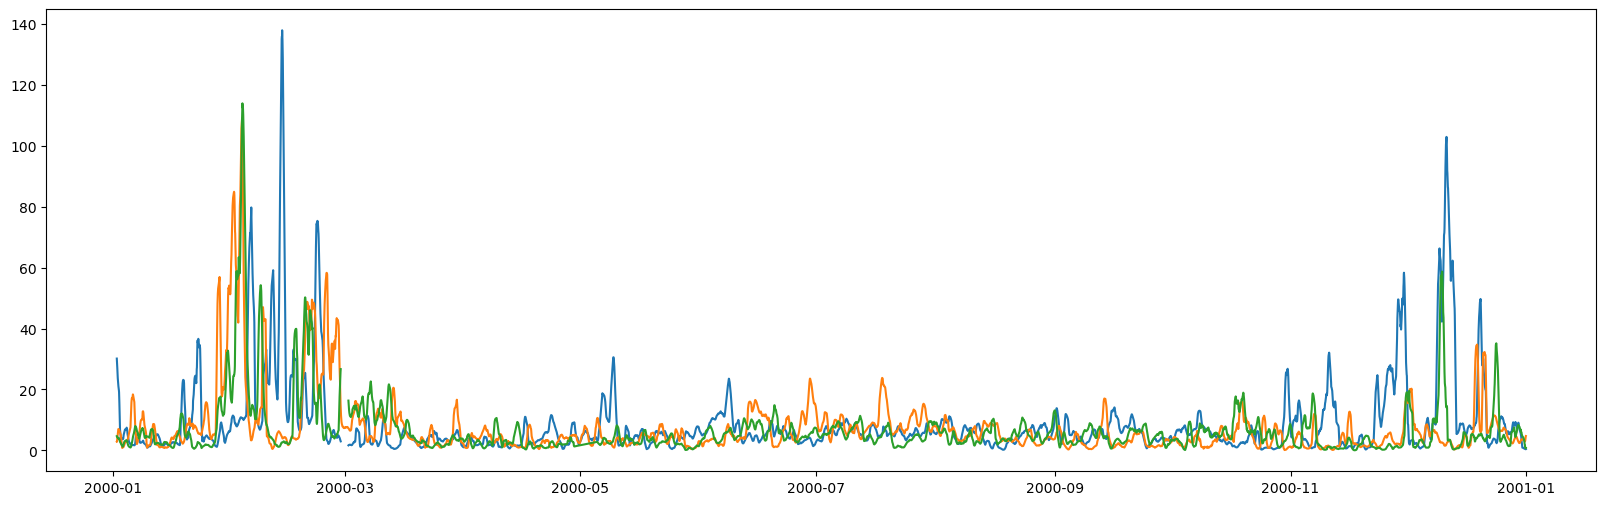

In [245]:
plt.figure(figsize=(20,6))
plt.plot(data_2023.rolling(window=24).mean())
plt.plot(data_2024.rolling(window=24).mean())
plt.plot(data_2025.rolling(window=24).mean())
plt.show()

In [199]:
def RMSE(df1, df2):
    return np.sqrt(np.nanmean((df1-df2)**2))

In [207]:
RMSE(data_2023.values, data_2024.values)

29.413447712004483

In [209]:
RMSE(data_2024.values, data_2025.values)

22.18809555691132